# Experiment 3: Six-parameter cantilever design

Three-dimensional cantilever clamped at $X=0$ and loaded at $X=L$ by a transverse force $F$
and an elastic support of stiffness $K$. The length, height, width, Young's modulus, Poisson
ratio and support stiffness are parameters, which enter as additional Chebyshev coordinates.
A single solve returns the tip response $\delta(\boldsymbol\xi)$ over the whole design space
(Sec. 4.3 and Fig. 7 of the paper).

In [1]:
import numpy as np
from scipy.interpolate import BarycentricInterpolator
from collections import defaultdict
from collections.abc import Callable
from typing import Any
from time import perf_counter
from pathlib import Path
from threadpoolctl import threadpool_limits
import warnings
import resource
from matplotlib.axes import Axes
from matplotlib.colors import Normalize

from seemps.state import MPS, MPSSum, Strategy, simplify, mps_tensor_product
from seemps.analysis.mesh import ChebyshevInterval, Mesh
from seemps.analysis.evaluation import evaluate_mps
from seemps.analysis.integration.vector_quadratures import vector_fejer
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform, mpo_chebyshev_transform

from seemps_galerkin.problem import (
    TensorField,
    BulkProblem,
    BoundaryProblem,
    BoundaryFace,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
)
from seemps_galerkin.dense.factories import vec_nd_chebyshev_transform, vec_chebyshev_endpoint
from seemps_galerkin.mps.factories import (
    mps_kron_expand,
    mps_zeros,
    mps_chebyshev_endpoint,
)
from seemps_galerkin.mps.defaults import DEFAULT_SVD_STRATEGY
from seemps_galerkin.mps.linear import AMEnSolver
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp
from seemps_galerkin.logger import Logger
from seemps_galerkin.typing import Vector, Matrix

from tools.data import get_distance_Lp, save_pkl, load_pkl
from tools.plot import set_plot_styles, create_subplots
from tools.solver import SolverDiagnostics
from seemps_galerkin.mps.preconditioning import ParametricBasisSolver

set_plot_styles()

L0, ΔL = 1.0, 0.2  # (0.8, 1.2) m
H0, ΔH = 0.20, 0.05  # (0.15, 0.25) m
W0, ΔW = 0.20, 0.05  # (0.15, 0.25) m
E0, ΔE = 70e9, 10e9  # (60e9, 80e9) Pa
ν0, Δν = 0.30, 0.05  # (0.25, 0.35)
K_MIN = 30e6  # (3e6, 300e6) N/m
F = 1e4  # N

## 1. Problem definition

In [2]:
def get_physical_parameters(ξ_params: Vector) -> tuple[float, ...]:
    ξ_L, ξ_H, ξ_W, ξ_E, ξ_ν, ξ_K = ξ_params
    L = L0 + ΔL * ξ_L
    H = H0 + ΔH * ξ_H
    W = W0 + ΔW * ξ_W
    E = E0 + ΔE * ξ_E
    ν_P = ν0 + Δν * ξ_ν
    K = K_MIN * 10**ξ_K
    return L, H, W, E, ν_P, K


def build_dense_problem(
    N_x: int, N_y: int, N_z: int, ξ_params: Vector
) -> tuple[BulkProblem[Vector], BoundaryProblem[Vector]]:
    d = m = 3

    # Get physical parameters from parametric coordinates
    L, H, W, E, ν_P, K = get_physical_parameters(ξ_params)
    # Divide the complete equation by E0 to improve numerical scaling.
    λ_1 = (E / E0) * ν_P / ((1.0 + ν_P) * (1.0 - 2.0 * ν_P))
    λ_2 = (E / E0) / (2.0 * (1.0 + ν_P))

    # Reference geometry
    itv_x = ChebyshevInterval(-1.0, 1.0, N_x, endpoints=False)
    itv_y = ChebyshevInterval(-1.0, 1.0, N_y, endpoints=False)
    itv_z = ChebyshevInterval(-1.0, 1.0, N_z, endpoints=False)
    mesh = Mesh([itv_x, itv_y, itv_z])

    I = np.ones(np.prod(mesh.dimensions))
    scales = np.array([2.0 / L, 2.0 / H, 2.0 / W])
    J_det = L * H * W / 8.0

    # =========================
    # Assemble the bulk problem
    # =========================

    principal = TensorField[Vector]((d, d, m, m), mesh.dimensions)
    for α in range(d):
        for β in range(d):
            factor = J_det * scales[α] * scales[β]
            for μ in range(m):
                for ν in range(m):
                    c = (
                        λ_1 * (α == μ) * (β == ν)
                        + λ_2 * (α == β) * (μ == ν)
                        + λ_2 * (α == ν) * (β == μ)
                    )
                    if c:
                        principal[α, β, μ, ν] = factor * c * I

    # No bulk reaction or body force
    reaction = TensorField[Vector]((m, m), mesh.dimensions)
    source = TensorField[Vector]((m,), mesh.dimensions)
    bulk = BulkProblem(mesh, principal, reaction, source)

    # =============================
    # Assemble the boundary problem
    # =============================

    bcs = []

    # Clamped left face
    face = BoundaryFace(0, is_left=True)
    face_shape = mesh.dimensions[1:]
    zeros = np.zeros(np.prod(face_shape))
    data = TensorField[Vector]((m,), face_shape)
    for μ in range(m):
        data[μ] = zeros
    bcs.append(DirichletBoundaryCondition(face, data))

    # Elastic restraint + right-face load
    face = BoundaryFace(0, is_left=False)
    face_shape = mesh.dimensions[1:]

    # Coordinates on the reference right face
    x = mesh.to_tensor(channels_first=True)
    x_2 = x[1][0, :, :]
    x_3 = x[2][0, :, :]

    reaction = TensorField[Vector]((m, m), face_shape)
    reaction[1, 1] = (K / (4.0 * E0)) * np.ones(np.prod(face_shape))

    data = TensorField[Vector]((m,), face_shape)
    data[1] = (-9.0 * F / (16.0 * E0) * (1.0 - x_2**2) * (1.0 - x_3**2)).reshape(-1)
    bcs.append(RobinBoundaryCondition(face, reaction, data))

    # Remaining faces are traction-free
    for dim in (1, 2):
        for is_left in (True, False):
            face = BoundaryFace(dim, is_left)
            face_shape = mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]
            reaction = TensorField[Vector]((m, m), face_shape)
            data = TensorField[Vector]((m,), face_shape)
            bcs.append(RobinBoundaryCondition(face, reaction, data))

    boundary = BoundaryProblem(mesh, bcs)

    return bulk, boundary


def solve_dense_problem(N_x: int, N_y: int, N_z: int, ξ_params: Vector) -> Vector:
    bulk, boundary = build_dense_problem(N_x, N_y, N_z, ξ_params)
    return solve_dense_bvp(bulk, boundary)

In [3]:
def build_mps_problem(
    n_x: int, n_y: int, n_z: int, n_ξ: int, strategy: Strategy = DEFAULT_SVD_STRATEGY
) -> tuple[BulkProblem[MPS], BoundaryProblem[MPS]]:
    d = m = 3
    sites_per_dimension = [n_x, n_y, n_z] + [n_ξ] * 6

    # Reference geometry
    itv_x = ChebyshevInterval(-1.0, 1.0, 2**n_x, endpoints=False)
    itv_y = ChebyshevInterval(-1.0, 1.0, 2**n_y, endpoints=False)
    itv_z = ChebyshevInterval(-1.0, 1.0, 2**n_z, endpoints=False)
    itv_ξ = ChebyshevInterval(-1.0, 1.0, 2**n_ξ, endpoints=False)
    mesh = Mesh([itv_x, itv_y, itv_z] + [itv_ξ] * 6)  # type: ignore

    # ===================================
    # Encode parametric dimensions in MPS
    # ===================================
    ξ = itv_ξ.to_vector()

    # Discretize the parameter ranges in Chebyshev--Gauss nodes
    L_ξ = L0 + ΔL * ξ
    H_ξ = H0 + ΔH * ξ
    W_ξ = W0 + ΔW * ξ
    E_ξ = (E0 + ΔE * ξ) / E0
    ν_ξ = ν0 + Δν * ξ
    K_ξ = K_MIN * 10.0**ξ / E0

    # Incomplete Lamé parameters
    λ1_ξ = ν_ξ / ((1.0 + ν_ξ) * (1.0 - 2.0 * ν_ξ))
    λ2_ξ = 1.0 / (2.0 * (1.0 + ν_ξ))

    # Encode them in MPS form using the SVD decomposition
    ψ_L = MPS.from_vector(L_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_H = MPS.from_vector(H_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_W = MPS.from_vector(W_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_E = MPS.from_vector(E_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_λ1 = MPS.from_vector(λ1_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_λ2 = MPS.from_vector(λ2_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    # Encode also the inverse dimensions for the Jacobian factor
    ψ_L_inv = MPS.from_vector(1.0 / L_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_H_inv = MPS.from_vector(1.0 / H_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_W_inv = MPS.from_vector(1.0 / W_ξ, [2] * n_ξ, strategy=strategy, normalize=False)

    # Expand with identities on remaining dimensions
    ψ_L = mps_kron_expand(ψ_L, sites_per_dimension, dim=3)
    ψ_H = mps_kron_expand(ψ_H, sites_per_dimension, dim=4)
    ψ_W = mps_kron_expand(ψ_W, sites_per_dimension, dim=5)
    ψ_E = mps_kron_expand(ψ_E, sites_per_dimension, dim=6)
    ψ_λ1 = mps_kron_expand(ψ_λ1, sites_per_dimension, dim=7)
    ψ_λ2 = mps_kron_expand(ψ_λ2, sites_per_dimension, dim=7)
    ψ_L_inv = mps_kron_expand(ψ_L_inv, sites_per_dimension, dim=3)
    ψ_H_inv = mps_kron_expand(ψ_H_inv, sites_per_dimension, dim=4)
    ψ_W_inv = mps_kron_expand(ψ_W_inv, sites_per_dimension, dim=5)

    # Complete the Lamé parameters
    ψ_λ1 = simplify(ψ_E * ψ_λ1, strategy=strategy)
    ψ_λ2 = simplify(ψ_E * ψ_λ2, strategy=strategy)

    # Compute the Jacobian determinant and factors
    ψ_J_det = (ψ_L * ψ_H * ψ_W) / 8.0
    ψ_scales = [2.0 * ψ_L_inv, 2.0 * ψ_H_inv, 2.0 * ψ_W_inv]

    # =========================
    # Assemble the bulk problem
    # =========================
    principal = TensorField[MPS]((d + 6, d + 6, m, m), mesh.dimensions)

    for α in range(d):
        for β in range(d):
            ψ_factor = ψ_J_det * ψ_scales[α] * ψ_scales[β]
            for μ in range(m):
                for ν in range(m):
                    ψ_terms = []
                    weights = []
                    if α == μ and β == ν:
                        ψ_terms.append(ψ_λ1)
                        weights.append(1.0)
                    if α == β and μ == ν:
                        ψ_terms.append(ψ_λ2)
                        weights.append(1.0)
                    if α == ν and β == μ:
                        ψ_terms.append(ψ_λ2)
                        weights.append(1.0)

                    if ψ_terms:
                        ψ_c = simplify(
                            MPSSum(weights, ψ_terms, check_args=False), strategy=strategy
                        )
                        principal[α, β, μ, ν] = ψ_factor * ψ_c

    reaction = TensorField[MPS]((m, m), mesh.dimensions)
    source = TensorField[MPS]((m,), mesh.dimensions)
    bulk = BulkProblem(mesh, principal, reaction, source)

    # =============================
    # Assemble the boundary problem
    # =============================

    bcs = []

    # Clamped left face
    face = BoundaryFace(0, is_left=True)
    face_shape = mesh.dimensions[1:]
    n_face = sum(sites_per_dimension[1:])
    data = TensorField[MPS]((m,), face_shape)
    for μ in range(m):
        data[μ] = mps_zeros(n_face)
    bcs.append(DirichletBoundaryCondition(face, data))

    # Elastic restraint + right-face load
    face = BoundaryFace(0, is_left=False)
    face_shape = mesh.dimensions[1:]
    face_sites = sites_per_dimension[1:]
    ψ_K_face = MPS.from_vector(K_ξ, [2] * n_ξ, strategy=strategy, normalize=False)
    ψ_K_face = mps_kron_expand(ψ_K_face, face_sites, dim=7)
    reaction = TensorField[MPS]((m, m), face_shape)
    reaction[1, 1] = 0.25 * ψ_K_face

    # Transverse load: -9F/16 (1 - x_2²)(1 - x_3²)
    x_2 = mesh.intervals[1].to_vector()
    x_3 = mesh.intervals[2].to_vector()
    ψ_profile_y = MPS.from_vector(1.0 - x_2**2, [2] * n_y, strategy=strategy, normalize=False)
    ψ_profile_z = MPS.from_vector(1.0 - x_3**2, [2] * n_z, strategy=strategy, normalize=False)
    ψ_profile_y = mps_kron_expand(ψ_profile_y, face_sites, dim=0)
    ψ_profile_z = mps_kron_expand(ψ_profile_z, face_sites, dim=1)
    ψ_traction = ψ_profile_y * ψ_profile_z
    data = TensorField[MPS]((m,), face_shape)
    data[1] = -9.0 * F / (16.0 * E0) * ψ_traction
    bcs.append(RobinBoundaryCondition(face, reaction, data))

    # Remaining faces are traction-free
    for dim in range(1, mesh.dimension):
        face_shape = mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]
        for is_left in (True, False):
            face = BoundaryFace(dim, is_left)
            reaction = TensorField[MPS]((m, m), face_shape)
            data = TensorField[MPS]((m,), face_shape)
            bcs.append(RobinBoundaryCondition(face, reaction, data))

    boundary = BoundaryProblem(mesh, bcs)
    return bulk, boundary

## 2. Dense reference

The tip response of a single design, from a dense solve at the same spatial resolution.

In [4]:
def get_tip_response(u_cheb: Vector, N_x: int, N_y: int, N_z: int) -> float:
    u_nodal = vec_nd_chebyshev_transform(
        u_cheb, (3, N_x, N_y, N_z), which_dimensions=(2, 3), inverse=True
    ).reshape(3, N_x, N_y, N_z)
    y = ChebyshevInterval(-1.0, 1.0, N_y, endpoints=False).to_vector()
    z = ChebyshevInterval(-1.0, 1.0, N_z, endpoints=False).to_vector()
    return float(
        -9.0
        / 16.0
        * np.einsum(
            "x,y,z,xyz->",
            vec_chebyshev_endpoint(N_x, is_left=False),
            vector_fejer(-1.0, 1.0, N_y) * (1.0 - y**2),
            vector_fejer(-1.0, 1.0, N_z) * (1.0 - z**2),
            u_nodal[1],
            optimize=True,
        )
    )


def solve_response_grid(designs: Matrix, N_x: int, N_y: int, N_z: int) -> Vector:
    return np.asarray(
        [get_tip_response(solve_dense_problem(N_x, N_y, N_z, ξ), N_x, N_y, N_z) for ξ in designs]
    )

## 3. Parametric QTT solution

One solve for each parametric resolution $N_\xi=2,4,8,16$. AMEn with Jacobi preconditioning
solves the system in an orthonormalized parametric basis (`seemps_galerkin.mps.preconditioning`), and the
response is checked against dense solves of 128 random designs. Timings use two BLAS threads,
and the peak memory is measured in a fresh process for each $N_\xi$. Results are stored in
`data/3_results_mps.pkl`.

In [5]:
TOLERANCE = 1e-10
RESPONSE_TOLERANCE = 1e-4
BLAS_THREADS = 2
SVD_STRATEGY = DEFAULT_SVD_STRATEGY.replace(tolerance=TOLERANCE, simplification_tolerance=TOLERANCE)
SOLVER = AMEnSolver(
    maxiter=24,
    rtol=1e-5,
    strategy=SVD_STRATEGY.replace(max_bond_dimension=192),
    preconditioner="jacobi",
    enrichment_rank=8,
    residual_rank=32,
)

n_range = range(1, 5)

In [6]:
def get_response_qtt(ψ_u: MPS, n_x: int, n_y: int, n_z: int, n_ξ: int) -> MPS:
    """Return the tip response at the Chebyshev--Gauss parameter nodes."""
    sites_per_dimension = [n_x, n_y, n_z] + [n_ξ] * 6
    y = ChebyshevInterval(-1.0, 1.0, 2**n_y, endpoints=False).to_vector()
    z = ChebyshevInterval(-1.0, 1.0, 2**n_z, endpoints=False).to_vector()
    ψ_quad_y = MPS.from_vector(
        vector_fejer(-1.0, 1.0, len(y)) * (1.0 - y**2),
        [2] * n_y,
        normalize=False,
        strategy=SVD_STRATEGY,
    )
    ψ_quad_z = MPS.from_vector(
        vector_fejer(-1.0, 1.0, len(z)) * (1.0 - z**2),
        [2] * n_z,
        normalize=False,
        strategy=SVD_STRATEGY,
    )
    ψ_quad_spatial = mps_tensor_product(
        [mps_chebyshev_endpoint(n_x, is_left=False), ψ_quad_y, ψ_quad_z],
        strategy=SVD_STRATEGY,
    )
    ψ_quad = MPS([np.array([0.0, -9.0 / 16.0, 0.0]).reshape(1, 3, 1), *ψ_quad_spatial])

    offsets = np.cumsum([1, *sites_per_dimension])
    for α in (1, 2):
        n = sites_per_dimension[α]
        transform = mpo_chebyshev_transform(n, inverse=True, strategy=SVD_STRATEGY).extend(
            ψ_u.size,
            sites=list(range(int(offsets[α]), int(offsets[α + 1]))),
            dimensions=[3] + [2] * (sum(sites_per_dimension) - n),
        )
        ψ_u = transform.apply(ψ_u)

    ρ = np.ones((1, 1), dtype=np.result_type(ψ_u[0], ψ_quad[0]))
    for core_u, core_quad in zip(ψ_u, ψ_quad):
        ρ = np.einsum("ab,api,bpj->ij", ρ, core_quad.conj(), core_u, optimize=True)
    core = np.einsum("a,apb->pb", ρ[0], ψ_u[len(ψ_quad)], optimize=True)[None, ...]
    ψ_response = MPS([core, *list(ψ_u)[len(ψ_quad) + 1 :]])
    return mps_chebyshev_transform(ψ_response, [n_ξ] * 6, inverse=True, strategy=SVD_STRATEGY)


def get_qtt_audit_designs(n_ξ: int, max_samples: int = 128) -> Matrix:
    N_ξ = 2**n_ξ
    count = min(max_samples, N_ξ**6)
    flat = np.random.default_rng(8128).choice(N_ξ**6, size=count, replace=False)
    indices = np.column_stack(np.unravel_index(flat, (N_ξ,) * 6))
    nodes = ChebyshevInterval(-1.0, 1.0, N_ξ, endpoints=False).to_vector()
    return nodes[indices]


@threadpool_limits.wrap(limits=BLAS_THREADS)
def run_mps(n_ξ: int) -> dict[str, Any]:
    N_ξ = 2**n_ξ
    n_x, n_y, n_z = 4, 3, 3
    designs = get_qtt_audit_designs(n_ξ)

    print(f"  Dense audit: {len(designs)} designs", flush=True)
    tick = perf_counter()
    dense_response = solve_response_grid(designs, 16, 8, 8)
    time_dense = perf_counter() - tick
    print(f"  Dense audit completed in {time_dense:.1f} s", flush=True)

    tick_total = perf_counter()
    print("  Building the QTT problem", flush=True)
    tick = perf_counter()
    bulk, boundary = build_mps_problem(n_x, n_y, n_z, n_ξ, strategy=SVD_STRATEGY)
    print(f"  QTT problem built in {perf_counter() - tick:.1f} s", flush=True)

    print("  Solving with AMEn + Jacobi in the parametric basis", flush=True)
    monitor = SolverDiagnostics(SOLVER, verify=False)
    solver = ParametricBasisSolver(
        n_ξ,
        spatial_bits=(n_x, n_y, n_z),
        lengths=(L0, H0, W0),
        num_parameters=6,
        dirichlet_axis=0,
        solver=monitor,
        strategy=SVD_STRATEGY,
    )
    Logger.activate(level=1, collect=True)
    try:
        tick = perf_counter()
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "error", message="AMEn did not converge", category=RuntimeWarning
            )
            ψ_u = solve_mps_bvp(bulk, boundary, strategy=SVD_STRATEGY, solver=solver)
        time_solve_end_to_end = perf_counter() - tick
        time_verification = monitor.time_native_residual + monitor.time_final_residual
        time_solve = time_solve_end_to_end - time_verification
        if not np.isfinite(monitor.residual) or monitor.residual > SOLVER.rtol:
            raise RuntimeError(
                f"AMEn global residual {monitor.residual:.3e} exceeds {SOLVER.rtol:.3e}"
            )
        maxbond_A = int(np.max(Logger.sink["solve.mps.A_dirichlet.bond_dimensions"][-1]))
    finally:
        Logger.deactivate()
        Logger.clear()
    print(
        f"  AMEn completed in {time_solve:.1f} s "
        f"with residual={monitor.residual:.3e}, "
        f"χ(A)={maxbond_A}, χ(u)={ψ_u.max_bond_dimension()}",
        flush=True,
    )

    print("  Reducing the solution to the tip response", flush=True)
    ψ_response = get_response_qtt(ψ_u, n_x, n_y, n_z, n_ξ)
    nodes = ChebyshevInterval(-1.0, 1.0, N_ξ, endpoints=False).to_vector()
    indices = np.argmin(np.abs(designs[:, :, None] - nodes[None, None, :]), axis=2)
    qtt_indices = np.array(
        [
            np.concatenate([np.unravel_index(index, (2,) * n_ξ) for index in design])
            for design in indices
        ]
    )
    qtt_response = np.asarray(np.real_if_close(evaluate_mps(ψ_response, qtt_indices)), dtype=float)
    if not np.all(np.isfinite(qtt_response)):
        raise RuntimeError("Nonfinite QTT response")
    pointwise_error = np.abs(qtt_response - dense_response) / np.abs(dense_response)
    time_end_to_end = perf_counter() - tick_total
    result = {
        "n_ξ": n_ξ,
        "time": time_end_to_end - time_verification,
        "memory": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2,
        "time_end_to_end": time_end_to_end,
        "time_verification": time_verification,
        "time_algorithm": monitor.time_algorithm,
        "time_basis": solver.time_basis,
        "time_dense": time_dense,
        "time_solve": time_solve,
        "residual": monitor.residual,
        "residual_kind": "native_global",
        "residual_basis": "transformed",
        "solver_mode": "parametric_basis",
        "sweeps": monitor.sweeps,
        "projected_residuals": monitor.projected_residuals,
        "solver_rtol": SOLVER.rtol,
        "solver_preconditioner": SOLVER.preconditioner,
        "solver_enrichment_rank": SOLVER.enrichment_rank,
        "solver_residual_rank": SOLVER.residual_rank,
        "solver_max_rank": SOLVER.strategy.get_max_bond_dimension(),
        "solver_svd_tolerance": SOLVER.strategy.get_tolerance(),
        "assembly_tolerance": TOLERANCE,
        "response_svd_tolerance": TOLERANCE,
        "blas_threads": BLAS_THREADS,
        "error_L2": get_distance_Lp(dense_response, qtt_response, p=2, relative=True),
        "error_max": float(np.max(pointwise_error)),
        "maxbond_A": maxbond_A,
        "maxbond_solver_A": solver.maxbond_A,
        "maxbond_u": ψ_u.max_bond_dimension(),
        "maxbond_response": ψ_response.max_bond_dimension(),
        "designs": designs,
        "dense_response": dense_response,
        "qtt_response": qtt_response,
        "response_cores": [np.asarray(core) for core in ψ_response],
    }
    print(
        f"  Done in {result['time']:.1f} s: "
        f"L² error={result['error_L2']:.3e}, "
        f"max error={result['error_max']:.3e}, "
        f"χ(response)={result['maxbond_response']}",
        flush=True,
    )
    return result


try:
    results_mps = load_pkl("data/3_results_mps.pkl")
except FileNotFoundError:
    results_mps = defaultdict(list)
    for iteration, n_ξ in enumerate(n_range, start=1):
        print(f"\n[{iteration}/{len(n_range)}] N_ξ={2**n_ξ}", flush=True)
        data = run_mps(n_ξ)
        for key, value in data.items():
            results_mps[key].append(value)
        print("  Saved partial results", flush=True)

    results_mps = dict(results_mps)
    if max(results_mps["error_L2"][-1], results_mps["error_max"][-1]) > RESPONSE_TOLERANCE:
        raise RuntimeError("The finest response does not meet the dense audit tolerance")
    save_pkl(results_mps, "data/3_results_mps.pkl")

## 4. Figures

In [7]:
results_mps = load_pkl("data/3_results_mps.pkl")
Path("figures/combined").mkdir(parents=True, exist_ok=True)


def make_tip_response(order: int, response_cores: list[np.ndarray]) -> Callable[[Matrix], Vector]:
    """Build the interpolated tip-response function from its nodal QTT."""
    sites = order.bit_length() - 1
    nodes = -np.cos(np.pi * (np.arange(order) + 0.5) / order)
    cardinal = BarycentricInterpolator(nodes, np.eye(order), rng=0)
    blocks = []
    for dim in range(6):
        block = response_cores[dim * sites]
        for core in response_cores[dim * sites + 1 : (dim + 1) * sites]:
            block = np.tensordot(block, core, axes=(-1, 0))
            block = block.reshape(block.shape[0], -1, block.shape[-1])
        blocks.append(block)

    def evaluate(designs: Matrix) -> Vector:
        designs = np.asarray(designs, dtype=float)
        if designs.ndim != 2 or designs.shape[1] != 6 or np.any(np.abs(designs) > 1):
            raise ValueError("Expected designs of shape (samples, 6) in [-1, 1]")
        values = []
        for chunk in np.array_split(designs, max(1, (len(designs) + 1023) // 1024)):
            environment = np.ones((len(chunk), 1))
            for dim, block in enumerate(blocks):
                environment = np.einsum(
                    "pa,anb,pn->pb",
                    environment,
                    block,
                    cardinal(chunk[:, dim]),
                    optimize=True,
                )
            values.append(np.real_if_close(environment[:, 0]).astype(float))
        return np.concatenate(values)

    return evaluate


response = make_tip_response(2 ** results_mps["n_ξ"][-1], results_mps["response_cores"][-1])

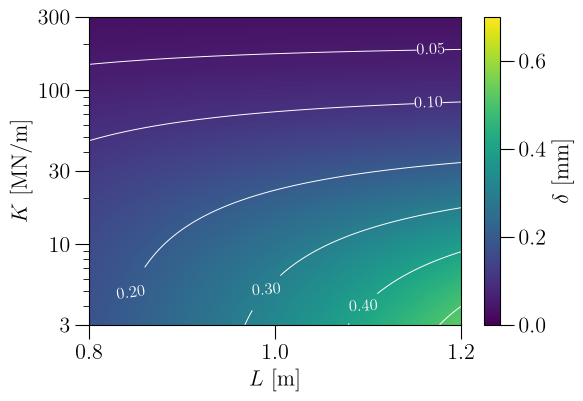

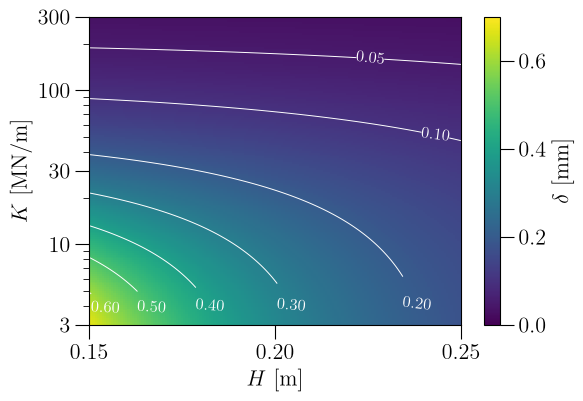

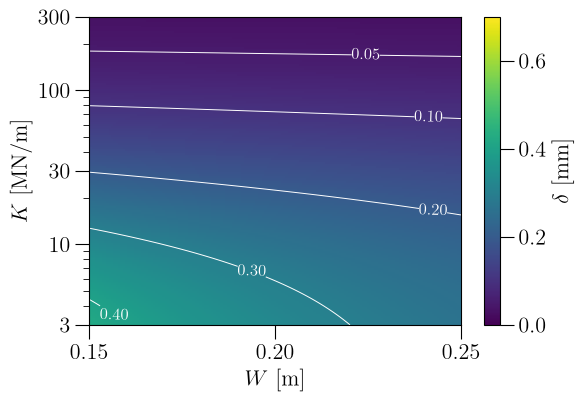

In [8]:
def plot_restraint(
    ax: Axes, parameter: int, values: Vector, label: str, show_colorbar: bool = True
) -> Any:
    coordinate = np.linspace(-1, 1, 161)
    X, Y = np.meshgrid(coordinate, coordinate)
    designs = np.zeros((X.size, 6))
    designs[:, parameter], designs[:, 5] = X.ravel(), Y.ravel()
    response_values = 1e3 * response(designs).reshape(X.shape)
    image = ax.pcolormesh(
        values,
        30 * 10**coordinate,
        response_values,
        shading="auto",
        cmap="viridis",
        norm=Normalize(0, 0.70),
        rasterized=True,
    )
    contours = ax.contour(
        values,
        30 * 10**coordinate,
        response_values,
        levels=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60],
        colors="white",
        linewidths=0.7,
        alpha=1.0,
    )
    ax.clabel(contours, fmt="%.2f", fontsize=12, inline_spacing=3)
    ax.set_yscale("log")
    ax.set_ylim(3, 300)
    ax.set_xlim(values[0], values[-1])
    ax.set_xticks(np.linspace(values[0], values[-1], 3))
    ax.set_yticks([3, 10, 30, 100, 300], labels=[3, 10, 30, 100, 300])
    ax.set_xlabel(label)
    ax.set_ylabel(r"$K$ [MN/m]")
    if show_colorbar:
        ax.figure.colorbar(image, ax=ax, label=r"$\delta$ [mm]")
    return image


coordinate = np.linspace(-1, 1, 161)
restraint_plots = (
    ("length", 0, L0 + ΔL * coordinate, r"$L$ [m]"),
    ("height", 1, H0 + ΔH * coordinate, r"$H$ [m]"),
    ("width", 2, W0 + ΔW * coordinate, r"$W$ [m]"),
)
for name, parameter, values, label in restraint_plots:
    fig, axs = create_subplots()
    plot_restraint(axs[0, 0], parameter, values, label)
    fig.savefig(f"figures/3_{name}_restraint.pdf", dpi=300, bbox_inches="tight")

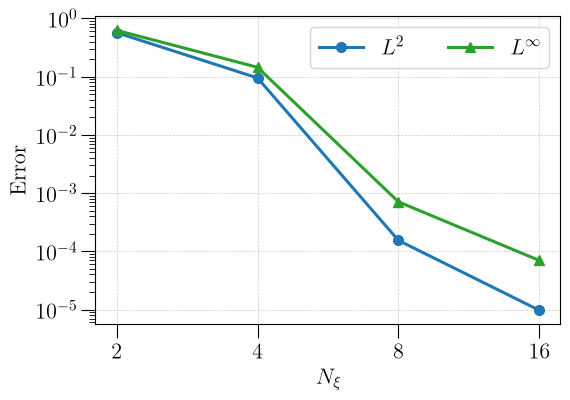

In [9]:
def plot_response_accuracy(ax: Axes) -> None:
    orders = 2 ** np.asarray(results_mps["n_ξ"])
    ax.loglog(orders, results_mps["error_L2"], "-o", label=r"$L^2$")
    ax.loglog(orders, results_mps["error_max"], "-^", label=r"$L^\infty$", color="C2")
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders, labels=orders)
    ax.set_xlabel(r"$N_\xi$")
    ax.set_ylabel("Error")
    ax.legend(loc="upper right", ncol=2)
    ax.grid(True)


fig, axs = create_subplots()
plot_response_accuracy(axs[0, 0])
fig.savefig("figures/3_response_accuracy.pdf", dpi=300, bbox_inches="tight")

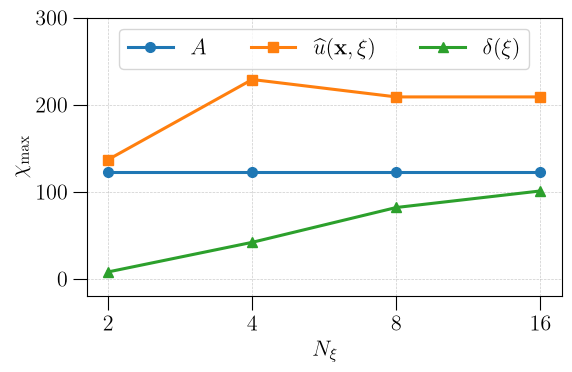

In [10]:
def plot_bond_dimensions(ax: Axes) -> None:
    orders = 2 ** np.asarray(results_mps["n_ξ"])
    for key, label, marker in (
        ("maxbond_A", r"$A$", "-o"),
        ("maxbond_u", r"$\widehat{u}(\mathbf{x}, \mathbf{\xi})$", "-s"),
        ("maxbond_response", r"$\delta(\mathbf{\xi})$", "-^"),
    ):
        ax.plot(orders, results_mps[key], marker, label=label)
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders, labels=orders)
    ax.set_xlabel(r"$N_\xi$")
    ax.set_ylabel(r"$\chi_{\max}$")
    ax.set_ylim(-20, 300)
    ax.legend(loc="upper center", ncol=3)
    ax.grid(True)


fig, axs = create_subplots()
plot_bond_dimensions(axs[0, 0])
fig.tight_layout()
fig.savefig("figures/3_bond_dimensions.pdf", dpi=300, bbox_inches="tight")

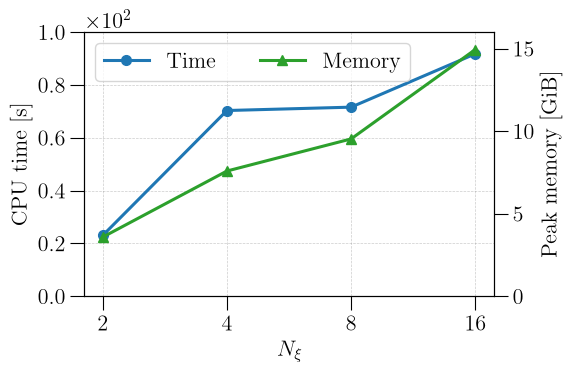

In [11]:
def plot_construction_time(ax: Axes) -> None:
    orders = 2 ** np.asarray(results_mps["n_ξ"])
    times = np.asarray(results_mps["time"])
    memory = np.asarray(results_mps["memory"])

    # Left axis: CPU time
    ax.plot(orders, times, "-o", label="Time")
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders, labels=orders)
    ax.set_ylim(0, 100)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax.set_xlabel(r"$N_\xi$")
    ax.set_ylabel("CPU time [s]")

    # Right axis: peak memory
    memory_ax = ax.twinx()
    memory_ax.plot(orders, memory, "-^", color="C2", label="Memory")
    memory_ax.set_ylim(0, 16)
    memory_ax.set_ylabel("Peak memory [GiB]")

    lines, labels = ax.get_legend_handles_labels()
    memory_lines, memory_labels = memory_ax.get_legend_handles_labels()
    ax.legend(lines + memory_lines, labels + memory_labels, loc="upper left", ncol=2)
    ax.grid(True, which="major")


fig, axs = create_subplots()
plot_construction_time(axs[0, 0])
fig.tight_layout()
fig.savefig("figures/3_construction_time.pdf", dpi=300, bbox_inches="tight")

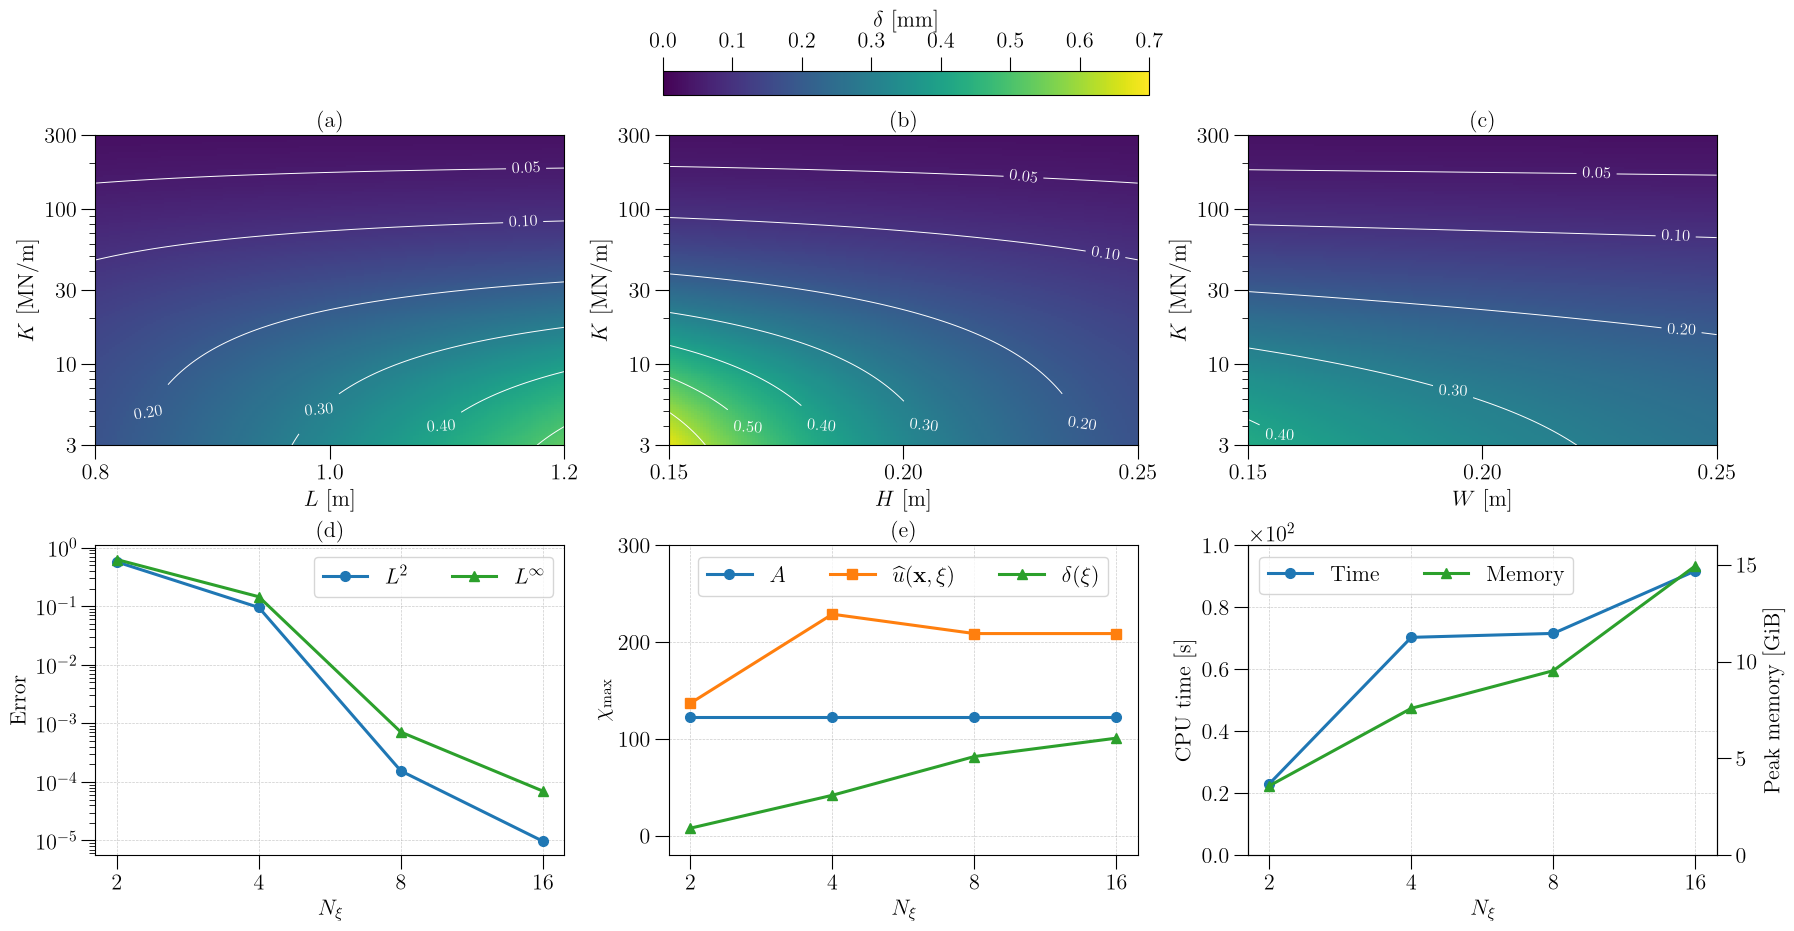

In [12]:
fig, axs = create_subplots(2, 3, height_px=460)
fig.set_layout_engine("constrained")
top_axes = [axs[0, col] for col in range(3)]

for ax, (_, parameter, values, label), title in zip(
    top_axes, restraint_plots, ("(a)", "(b)", "(c)")
):
    image = plot_restraint(ax, parameter, values, label, show_colorbar=False)
    ax.set_title(title)

fig.colorbar(
    image,
    ax=top_axes,
    orientation="horizontal",
    location="top",
    shrink=0.3,
    pad=0.05,
    label=r"$\delta$ [mm]",
)

plot_response_accuracy(axs[1, 0])
axs[1, 0].set_title("(d)")
plot_bond_dimensions(axs[1, 1])
axs[1, 1].set_title("(e)")
plot_construction_time(axs[1, 2])

fig.savefig("figures/combined/3_combined.pdf", dpi=300)